<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/03_computer_vision/10_video_classification_app_ucf101.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎬 Application · Video classification: recognising human actions

A video is a stack of images **plus time**. Is this person *dunking* or just *playing basketball*? *Applying
lipstick* or *eye make-up*? Some actions can be guessed from a single frame (the background gives it away), others
only make sense with motion.

Video understanding powers sports highlights, content moderation and search on video platforms, gesture control,
assistive technologies, wildlife behaviour studies…

**A short history**
- **2012 · UCF101** (University of Central Florida): 13 320 YouTube clips of **101 human actions**. For years *the*
  action recognition benchmark.
- **2014 · Two-stream networks**: one CNN looks at frames (appearance), another at optical flow (motion).
- **2017 · Kinetics** (DeepMind): 300 000 clips, 400 then 700 classes. Big data arrives in video, with 3D CNNs (I3D).
- **2022 · VideoMAE**: a video transformer pre-trained by **hiding 90% of the video** (space-time "tubes") and
  learning to reconstruct it. Masked pre-training makes video models data-efficient.

**Dataset:** a 10-class subset of UCF101 (≈ 400 clips, 171 MB).
**Your mission:** build a strong **image-based baseline**, then fine-tune a **video transformer**, and avoid a nasty
leakage trap on the way. **Metric:** accuracy.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "av"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import logging, re, time
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import av
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import timm
import transformers
from transformers import VideoMAEForVideoClassification
import huggingface_hub
huggingface_hub.utils.logging.set_verbosity_error()
huggingface_hub.utils.disable_progress_bars()
transformers.logging.set_verbosity_error()

DEVICE = get_device()
quest("Recognise human actions", chapter="Track 3 · Computer vision · Video classification", xp=250)

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Recognise human actions
   Track 3 · Computer vision · Video classification
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Download and decode videos 📼

A video file is compressed: we use **PyAV** (Python bindings of FFmpeg, works on Windows, macOS and Linux) to decode
it and **sample 16 frames evenly** across the clip. Each clip becomes an array `(16, 224, 224, 3)`.

In [3]:
root = download_and_extract("https://huggingface.co/datasets/sayakpaul/ucf101-subset/resolve/main/UCF101_subset.tar.gz",
                            "ucf101_subset", marker="UCF101_subset") / "UCF101_subset"
clips = pd.DataFrame([{"path": p, "split": p.parts[-3], "label": p.parts[-2],
                       "group": int(re.search(r"_g(\d+)_", p.name).group(1))} for p in sorted(root.rglob("*.avi"))])
CLASSES = sorted(clips["label"].unique())
print(len(clips), "clips ·", len(CLASSES), "classes:", ", ".join(CLASSES))
pd.crosstab(clips["label"], clips["split"])

405 clips · 10 classes: ApplyEyeMakeup, ApplyLipstick, Archery, BabyCrawling, BalanceBeam, BandMarching, BaseballPitch, Basketball, BasketballDunk, BenchPress


split,test,train,val
label,,,
ApplyEyeMakeup,6,30,3
ApplyLipstick,4,30,3
Archery,7,30,3
BabyCrawling,9,30,3
BalanceBeam,4,30,3
BandMarching,9,30,3
BaseballPitch,10,30,3
Basketball,11,30,3
BasketballDunk,6,30,3


decoded 405 clips in 47s · one clip = (16, 3, 224, 224)


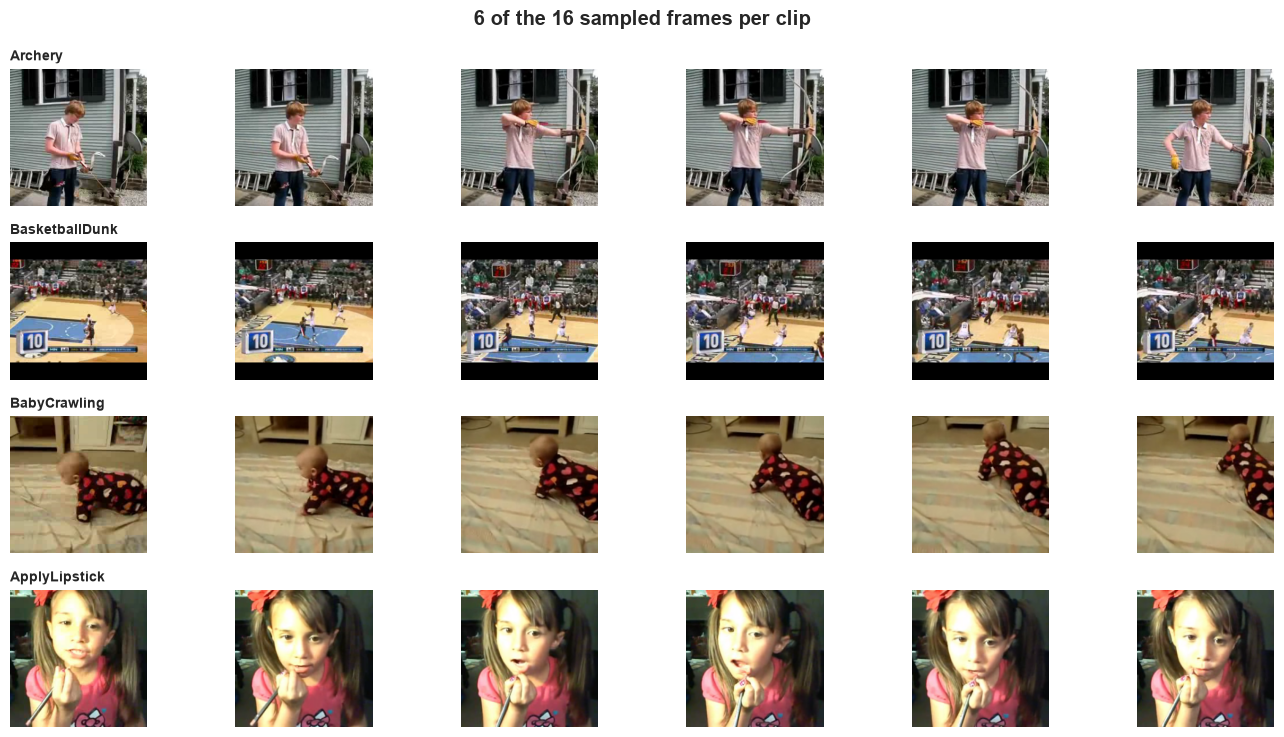

In [4]:
N_FRAMES, SIZE = 16, 224

def load_clip(path, n=N_FRAMES, size=SIZE):
    """Decode a video, keep n evenly spaced frames, resize the short side to `size` and center-crop."""
    with av.open(str(path)) as container:
        frames = [f.to_ndarray(format="rgb24") for f in container.decode(video=0)]
    idx = np.linspace(0, len(frames) - 1, n).round().astype(int)
    out = []
    for i in idx:
        img = torch.from_numpy(frames[i]).permute(2, 0, 1).float()
        h, w = img.shape[1:]
        scale = size / min(h, w)
        img = nn.functional.interpolate(img[None], size=(round(h * scale), round(w * scale)), mode="bilinear", align_corners=False)[0]
        top, left = (img.shape[1] - size) // 2, (img.shape[2] - size) // 2
        out.append(img[:, top:top + size, left:left + size].clamp(0, 255).byte())
    return torch.stack(out)            # (n, 3, size, size) uint8

t0 = time.time()
videos = {p: load_clip(p) for p in clips["path"]}
print(f"decoded {len(videos)} clips in {time.time() - t0:.0f}s · one clip = {tuple(next(iter(videos.values())).shape)}")

ex = clips.groupby("label").first()["path"]
fig, axes = plt.subplots(4, 6, figsize=(14, 7.5))
for r, label in enumerate(["Archery", "BasketballDunk", "BabyCrawling", "ApplyLipstick"]):
    v = videos[ex[label]]
    for c, i in enumerate(np.linspace(0, N_FRAMES - 1, 6).astype(int)):
        axes[r, c].imshow(v[i].permute(1, 2, 0)); axes[r, c].axis("off")
    axes[r, 0].set_title(label, loc="left", fontsize=10)
plt.suptitle("6 of the 16 sampled frames per clip", fontweight="bold"); plt.tight_layout(); plt.show()

## 2. 🕵️ The leakage trap: groups

UCF101 clips come in **groups** (`_g07_` in the file name): all clips of a group were cut from the **same long
YouTube video**: same person, same room, same lighting. If clips of the same group are in train *and* test, a model
can recognise the room instead of the action, and the test score is inflated.

The official UCF101 protocol therefore splits **by group** (groups 1-7 for testing). Let's check the provided split:

In [5]:
g = {s: set(clips.loc[clips.split == s, "group"]) for s in ["train", "val", "test"]}
print("groups shared by train and test:", sorted(g["train"] & g["test"]))

groups shared by train and test: [2, 3, 4, 5, 6, 9, 11, 12, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


Almost every test group also appears in training: the provided split leaks! We rebuild an honest split following the
official convention: **test = groups 1-7**, **validation = groups 8-10**, **train = groups 11-25**.

In [6]:
clips["split"] = np.select([clips.group <= 7, clips.group <= 10], ["test", "val"], "train")
print(clips["split"].value_counts().to_string())
checkpoint("video/leakage", xp=40, msg="Leakage avoided!")

split
train    236
test     126
val       43
✅ Checkpoint · video/leakage (+40 XP) Leakage avoided!
   █████████░░░░░░░░░░░░░░░ 40/100 XP


## 3. Baseline: an image model on frames 🖼️

How far can we go **without modelling time**? We encode frames with a pre-trained image network (ConvNeXt-Nano,
ImageNet) and train a logistic regression on top:
- **A. middle frame only**: one image per clip,
- **B. average of 8 frames**: a cheap way to summarise the whole clip.

In [7]:
encoder = timm.create_model("convnext_nano.in12k_ft_in1k", pretrained=True, num_classes=0).to(DEVICE).eval()
cfg = timm.data.resolve_data_config({}, model=encoder)
MEAN, STD = torch.tensor(cfg["mean"])[:, None, None], torch.tensor(cfg["std"])[:, None, None]

@torch.no_grad()
def frame_features(v, frames):
    x = (v[frames].float() / 255 - MEAN) / STD
    return encoder(x.to(DEVICE)).cpu().numpy()

feats_mid = np.stack([frame_features(videos[p], [N_FRAMES // 2])[0] for p in clips["path"]])
feats_avg = np.stack([frame_features(videos[p], list(range(0, N_FRAMES, 2))).mean(0) for p in clips["path"]])

from sklearn.linear_model import LogisticRegression
y = clips["label"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
tr, te = (clips.split == "train").to_numpy(), (clips.split == "test").to_numpy()

lb = Leaderboard("ucf101_subset", metric="test_accuracy")
lb.add("Random guess", 1 / len(CLASSES))
for name, F in [("Image model · middle frame", feats_mid), ("Image model · mean of 8 frames", feats_avg)]:
    clf = LogisticRegression(max_iter=3000, C=0.5).fit(F[tr], y[tr])
    lb.add(name, clf.score(F[te], y[te]))
lb.show()

📋 Random guess: test_accuracy = 0.10000
📋 Image model · middle frame: test_accuracy = 0.92857  👑 new best!
📋 Image model · mean of 8 frames: test_accuracy = 0.95238  👑 new best!


,,model,test_accuracy
rank,,,
1,🥇,Image model · mean of 8 frames,0.95238
2,🥈,Image model · middle frame,0.92857
3,🥉,Random guess,0.10000


A strong baseline: many UCF101 actions are recognisable from the scene alone (a pool → diving; a beam → balance beam).
Averaging frames helps a bit. The real question: does a model that understands **motion** do better?

In [8]:
checkpoint("video/baseline", xp=40)

✅ Checkpoint · video/baseline (+40 XP)
   ███████████████████░░░░░ 80/100 XP


## 4. VideoMAE: a transformer that watches the whole clip 🎞️

VideoMAE cuts the 16×224×224 clip into **space-time patches** ("tubes" of 2 frames × 16×16 pixels), and a transformer
lets every patch attend to every other one, across space **and** time. We use the *small* version (22 M parameters)
already fine-tuned on Kinetics-400 by its authors.

First, out of the box: what does it see in our clips, with its 400 Kinetics classes?

In [9]:
VMAE = "MCG-NJU/videomae-small-finetuned-kinetics"
vmae_mean, vmae_std = torch.tensor([0.485, 0.456, 0.406])[:, None, None], torch.tensor([0.229, 0.224, 0.225])[:, None, None]

def to_vmae(v):
    return (v.float() / 255 - vmae_mean) / vmae_std        # (16, 3, 224, 224), what VideoMAE expects

kinetics_model = VideoMAEForVideoClassification.from_pretrained(VMAE).to(DEVICE).eval()
rows = []
with torch.no_grad():
    for label in ["Archery", "BasketballDunk", "BenchPress", "BandMarching", "ApplyEyeMakeup"]:
        p = clips[(clips.split == "test") & (clips.label == label)]["path"].iloc[0]
        probs = kinetics_model(pixel_values=to_vmae(videos[p])[None].to(DEVICE)).logits.softmax(-1)[0].cpu()
        top = probs.topk(3)
        rows.append({"true UCF101 action": label,
                     "Kinetics top-3 guesses": " · ".join(f"{kinetics_model.config.id2label[int(i)]} ({float(s):.0%})"
                                                          for s, i in zip(top.values, top.indices))})
pd.DataFrame(rows)

,true UCF101 action,Kinetics top-3 guesses
0,Archery,hula hooping (23%) · archery (13%) · roller sk...
1,BasketballDunk,dunking basketball (74%) · playing basketball ...
2,BenchPress,bench pressing (83%) · situp (0%) · air drummi...
3,BandMarching,marching (82%) · celebrating (3%) · zumba (1%)
4,ApplyEyeMakeup,applying cream (36%) · whistling (10%) · stick...


Impressive zero-shot guesses: Kinetics contains many related actions. Now we **fine-tune** it on our 10 classes: we
replace the 400-class head by a 10-class one and train the whole network for a few epochs.

In [10]:
class ClipDataset(Dataset):
    def __init__(self, df, train=False):
        self.paths, self.y, self.train = df["path"].tolist(), df["label"].map({c: i for i, c in enumerate(CLASSES)}).tolist(), train

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        v = videos[self.paths[i]]
        if self.train and torch.rand(1) < 0.5:
            v = v.flip(-1)                                   # horizontal flip of every frame
        return to_vmae(v), self.y[i]

train_dl = DataLoader(ClipDataset(clips[clips.split == "train"], train=True), batch_size=4, shuffle=True, num_workers=NUM_WORKERS)
val_dl = DataLoader(ClipDataset(clips[clips.split == "val"]), batch_size=8, num_workers=NUM_WORKERS)
test_dl = DataLoader(ClipDataset(clips[clips.split == "test"]), batch_size=8, num_workers=NUM_WORKERS)

seed_everything(SEED)
model = VideoMAEForVideoClassification.from_pretrained(
    VMAE, num_labels=len(CLASSES), id2label=dict(enumerate(CLASSES)), label2id={c: i for i, c in enumerate(CLASSES)},
    ignore_mismatched_sizes=True,                            # the 400-class head is replaced by a fresh 10-class head
).to(DEVICE)

@torch.no_grad()
def accuracy(dl):
    model.eval(); correct = n = 0; preds = []
    for x, yb in dl:
        p = model(pixel_values=x.to(DEVICE)).logits.argmax(-1).cpu()
        preds.append(p); correct += (p == yb).sum().item(); n += len(yb)
    return correct / n, torch.cat(preds).numpy()

EPOCHS = 3
opt = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.05)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=5e-5, total_steps=EPOCHS * len(train_dl), pct_start=0.2)
for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); total = 0
    for x, yb in train_dl:
        out = model(pixel_values=x.to(DEVICE), labels=yb.to(DEVICE))
        opt.zero_grad(); out.loss.backward(); opt.step(); sched.step()
        total += out.loss.item() * len(yb)
    print(f"epoch {epoch} · train loss {total / len(train_dl.dataset):.3f} · val acc {accuracy(val_dl)[0]:.3f} · {time.time() - t0:.0f}s")

test_acc, test_pred = accuracy(test_dl)
lb.add("VideoMAE-small (Kinetics) · fine-tuned 3 epochs", test_acc)
lb.show()

epoch 1 · train loss 1.919 · val acc 0.767 · 180s


epoch 2 · train loss 0.845 · val acc 0.884 · 217s


epoch 3 · train loss 0.504 · val acc 0.860 · 169s


📋 VideoMAE-small (Kinetics) · fine-tuned 3 epochs: test_accuracy = 0.92857


,,model,test_accuracy
rank,,,
1,🥇,Image model · mean of 8 frames,0.95238
2,🥈,Image model · middle frame,0.92857
3,🥉,VideoMAE-small (Kinetics) · fine-tuned 3 epochs,0.92857
4,,Random guess,0.10000


In [11]:
checkpoint("video/videomae", xp=60)

✅ Checkpoint · video/videomae (+60 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ████░░░░░░░░░░░░░░░░░░░░ 140/300 XP


**Surprised?** With ~240 training clips and 3 epochs on a laptop, the 22 M-parameter video transformer does
not beat the frame-based baseline here. That is one of the most common lessons of real competitions: a **strong,
simple baseline** built on a good pre-trained model is very hard to beat, and big models need more data, more epochs
or more compute to shine. On UCF101's 101 classes, or on datasets where motion is the only clue (e.g. *Something-Something*:
"pushing something from left to right"), video models win by a wide margin.

## 5. Where does each approach fail? 🔎

In [12]:
from sklearn.metrics import confusion_matrix
y_test = y[te]
clf = LogisticRegression(max_iter=3000, C=0.5).fit(feats_avg[tr], y[tr])
per_class = pd.DataFrame({
    "clips": pd.Series(y_test).value_counts().sort_index().values,
    "image model (mean of 8 frames)": [(clf.predict(feats_avg[te])[y_test == c] == c).mean() for c in range(len(CLASSES))],
    "VideoMAE fine-tuned": [(test_pred[y_test == c] == c).mean() for c in range(len(CLASSES))],
}, index=CLASSES).round(2)
per_class.style.background_gradient(cmap="Greens", subset=per_class.columns[1:], vmin=0, vmax=1).format(precision=2)

,clips,image model (mean of 8 frames),VideoMAE fine-tuned
ApplyEyeMakeup,11,0.64,0.73
ApplyLipstick,11,1.00,0.91
Archery,12,1.00,1.00
BabyCrawling,12,1.00,1.00
BalanceBeam,12,1.00,0.75
BandMarching,15,1.00,1.00
BaseballPitch,11,0.82,0.82
Basketball,16,1.00,1.00
BasketballDunk,11,1.00,1.00
BenchPress,15,1.00,1.00


Look at fine-grained pairs like *ApplyEyeMakeup* vs *ApplyLipstick*: same scene (a face, a hand), different motion.
That's where watching time can pay off, while scene-based classes (archery, band marching, bench press) are already
solved by the image model. The two models make different mistakes: averaging their probabilities would be a natural
next step (remember the ensembling lesson of the playbook). On a small test set (each clip ≈ 1.2% of accuracy), keep in
mind that differences of a few clips are within noise.

## 🏁 Mission accomplished

You decoded videos, caught a group-leakage trap, built a frame-based baseline and fine-tuned a video transformer.

### 🚀 Your turn (bonus XP)
1. Evaluate both models on the *original* (leaky) split: how much higher are the scores? That gap is pure leakage.
2. Fine-tune for more epochs, or add augmentation (random crop, temporal jitter: sample frames at random offsets).
3. Replace the frame average by a small 1D convolution or GRU over the 16 frame embeddings.
4. Try `MCG-NJU/videomae-base-finetuned-kinetics` (87 M parameters) if you have a GPU.

In [13]:
checkpoint("video/complete", xp=110)
badge("Action Director", "🎬")
progress()

✅ Checkpoint · video/complete (+110 XP)
   ██████████████████░░░░░░ 250/300 XP
╔════════════════════════════════════╗
║ 🎬  BADGE UNLOCKED: Action Director ║
╚════════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 4
Badges: 🎬 Action Director
